# socio4health data paper workflow, 2019–2024

Builds a harmonized dataset from four household surveys with the **extract → harmonize → load** pipeline of socio4health:

| Survey | Country | Subnational unit of the shares | Years with data in 2019–2024 |
|---|---|---|---|
| GEIH (DANE) | Colombia | Department | 2019–2024 |
| ENAHO (INEI) | Peru | District (`UBIGEO`) | 2019–2024 |
| PNAD Contínua (IBGE) | Brazil | State capital | 2019–2024 (2020–2021: visit 5, person variables only) |
| ENHOGAR (ONE) | Dominican Republic | Region | 2019, 2021, 2022, 2024 |

**Outputs**

- `households` and `persons`: one row per surveyed household / person and year, with its survey, IDs, subnational unit, expansion factor (`WEIGHT`) and every harmonized variable as its **harmonized code** (age as a number). Any estimate is a weighted query on these tables.
- `shares`: weighted share of each category per unit and year, computed from the records, with the unit's `POPULATION` and `HOUSEHOLDS` (sum of weights). Educational attainment is computed for people aged 25 and over.
- `codebook`: the label of every code.

Every survey year runs on its own and is checkpointed: a failing year is reported and skipped, and running the notebook again only processes what is missing. Details of each year go to `OUTPUT_DIR/logs/`.

## 1. Configuration

In [1]:
import contextlib, hashlib, json, os, re, time, traceback
from datetime import datetime, timezone
from pathlib import Path

import pandas as pd
from tqdm.auto import tqdm

import socio4health
from socio4health import Extractor, Harmonizer, s4h_export, s4h_set_log_level
from socio4health.utils import extractor_utils, harmonizer_utils
from socio4health.utils.harmonizer_utils import (
    _clean_column_name, _normalize_columns, apply_value_mappings, harmonize_columns_by_year, mapping_source_columns,
    merge_factor, s4h_code_from_flags, use_person_factor,
)

DATA_ROOT = Path(os.environ.get("S4H_DATA_ROOT", r"D:\EQUIPO\Documents HDD\Harmonize"))
OUTPUT_DIR = DATA_ROOT / "OUTPUT_data_paper_2019_2024"
FIRST_YEAR, LAST_YEAR = 2019, 2024
SURVEYS_TO_RUN = ["GEIH", "ENAHO", "PNADC", "ENHOGAR"]
EDUCATION_MIN_AGE = 25   # educational attainment in `shares` is computed for people this old or older
RESUME = True            # reuse finished years
CACHE_PARQUET = True     # text files are converted once to Parquet next to the raw files: the first run
                         # is slower and uses more disk, later runs skip parsing the text
EXPORT_FORMATS = ["csv", "parquet", "duckdb"]   # CSV only for `shares` and `codebook` (records are too large)

MAPPINGS_DIR = next(p for p in (Path.cwd(), Path.cwd() / "data_paper") if (p / "harmonized_mapping.json").exists())
DUCKDB_FILE = OUTPUT_DIR / "socio4health_data_paper.duckdb"
for sub in ("checkpoints", "logs", "_extractor"):
    (OUTPUT_DIR / sub).mkdir(parents=True, exist_ok=True)
s4h_set_log_level("WARNING")
print("socio4health", socio4health.__version__, "| data:", DATA_ROOT, "| output:", OUTPUT_DIR)

socio4health 1.0.14 | data: D:\EQUIPO\Documents HDD\Harmonize | output: D:\EQUIPO\Documents HDD\Harmonize\OUTPUT_data_paper_2019_2024


## 2. Surveys

`column_mapping` renames raw columns to harmonized names and `value_mapping` recodes their categories (files in this folder). `household_key` and `person_key` identify each record; they are used to join the variables of different modules (e.g. sex from one file and education from another) into one row per household and one row per person. Only the mapped columns, the keys and the weights are kept, so the rest of each file is never loaded. Survey-specific rules:

- **GEIH**: the weight is `FEX_C18` (CNPV 2018 projection). In 2020 it comes from a separate projection file that leaves out 8 of the departments added that year (81, 85, 86, 91, 94, 95, 97, 99); their households use `FEX_C`, which is on the same CNPV 2018 base. Each month's sample is expanded to the whole population, so the weight is divided by 12 (`periods_per_year`). Up to 2019 the files are split by area and the area is only in the file name: `Cabecera` is urban (`CLASE = 1`) and `Resto` rural (`CLASE = 2`). `Área` files repeat `Cabecera` households and are skipped.
- **ENAHO**: only completed or partly completed interviews (`RESULT` 1-2), and only usual residents: members not away 30 days or more (`P204 = 1, P205 = 2`) and non-members present 30 days or more (`P204 = 2, P206 = 1`), as INEI does. The household key is `CONGLOME + VIVIENDA + HOGAR` (`VIVIENDA` alone is not unique). Literacy (`P302`) is only asked to people below completed primary; the others count as literate (`fill_missing`: their education level, codes 4-11, maps to literate). Households use the household factor `FACTOR07`; persons use the population factor `FACPOB07` of the household-members module (200), joined to the other person modules by `CODPERSO`.
- **PNADC**: fixed-width files read with the IBGE dictionary published with each year (`PNADC/<year>/dicionario*.xls`), because the layout changes between years. Annual visit 1 files; 2020 and 2021 use visit 5, the annual files IBGE released for the pandemic years, which have no housing module. One file holds persons and their household's variables; households are taken from it. Cooking fuel: the most used one (`S01016B`) is only asked when the household uses 2+ fuels; otherwise it is the only "yes" among `S01016A1`-`A5`. Shares are by state capital.
- **ENHOGAR**: one mapping file per year; the keys changed in 2021 (MICS 2019: `HH1 + HH2`, line `HL1`). In 2019 (MICS) water is the source for household use, `WS2`, which is only asked when drinking water is bottled; the other households take their drinking-water source `WS1`. This is declared in the mapping as `"WS2|WS1": "H_WATER"`: a key listing several raw columns takes the first non-empty one.
- Ethnicity is mapped as `P_ETHNICITY` but called `P_ETHNIC` in `harmonized_mapping.json`; it is renamed for all surveys.

In [2]:
SURVEYS = {
    "GEIH": {
        "country": "COL", "years": range(2007, 2026), "path": "GEIH/{year}",
        "reader": {"down_ext": [".csv"], "sep": ";", "on_bad_lines": "skip"},
        "file_groups": [
            {"pattern": r"(?i)[._]csv_\s*Cabecera\s*-", "assign": {"CLASE": "1"}},
            {"pattern": r"(?i)[._]csv_\s*Resto\s*-", "assign": {"CLASE": "2"}},
            {"pattern": r"(?i)^(?!.*[._]csv_\s*(Cabecera|Resto|.rea)\s*-)"},   # not split by area
        ],
        "column_mapping": "col_mapping/column_mapping.json",
        "value_mapping": "col_mapping/geih_mapping.json",
        "factor": {"factor_col": "FEX_C18", "id_col": "DIRECTORIO", "fallback_col": "FEX_C"},
        "household_key": [["DIRECTORIO", "SECUENCIA_P", "MES"]],
        "person_key": [["ORDEN"]],
        "periods_per_year": 12,   # each monthly sample is expanded to the whole population
        "group_col": "ADMIN_DIVISION",
    },
    "ENAHO": {
        "country": "PER", "years": range(2004, 2025), "path": "ENAHO/{year}",
        "reader": {"down_ext": [".sav"]},
        "column_mapping": "per_mapping/column_mapping.json",
        "value_mapping": "per_mapping/enaho_mapping.json",
        "factor": {"factor_col": "FACTOR07", "id_col": ["CONGLOME", "VIVIENDA", "HOGAR"]},
        # person modules are weighted with the population factor of the household-members module
        "person_factor": {"factor_col": "FACPOB07", "id_col": ["CONGLOME", "VIVIENDA", "HOGAR", "CODPERSO"]},
        # Only completed or partly completed interviews (RESULT 1-2), as INEI does: refusals, absences and
        # empty dwellings have no data
        "keep_rows": {"RESULT": [1, 2]},
        # Usual residents only, as INEI does: members not away 30+ days (P204 = 1, P205 = 2) and non-members
        # present 30+ days (P204 = 2, P206 = 1). Every person module carries P204-P206
        "keep_rows_any": [{"P204": [1], "P205": [2]}, {"P204": [2], "P206": [1]}],
        # Literacy (P302) is only asked below completed primary: in the table that asks it, the people who were
        # not asked and completed primary or more (P301A 4-11) take that level, which the value mapping counts
        # as literate. Other blanks (e.g. 2020 phone interviews) stay Missing
        "fill_missing": {"P302": {"from": "P301A", "values": [4, 5, 6, 7, 8, 9, 10, 11]}},
        "household_key": [["CONGLOME", "VIVIENDA", "HOGAR"]],
        "person_key": [["CODPERSO"]],
        "group_col": "ADMIN_DIVISION",
    },
    "PNADC": {
        "country": "BRA", "years": range(2012, 2026),
        "path": "PNADC/{year}", "reader": {"down_ext": [".txt"]},
        "ibge_dictionary": "dicionario*.xls",   # layout of each year, read from its own folder
        "column_mapping": "pnadc_mapping/column_mapping.json",
        "value_mapping": "pnadc_mapping/pnadc_mapping.json",
        "household_key": [["UPA", "V1008", "V1014"]],
        "person_key": [["V2003"]],
        # Cooking fuel: S01016B ("most used") is only asked when 2+ fuels are used; otherwise the fuel is the
        # only "yes" among S01016A1-A5. S01016F holds it, and the mapping uses "S01016B|S01016F"
        "derive_from_flags": {"S01016F": {"S01016A1": 1, "S01016A2": 2, "S01016A3": 3, "S01016A4": 4, "S01016A5": 5}},
        "group_col": "ADMIN_DIVISION_2",
    },
    "ENHOGAR": {
        "country": "DOM", "years": [2006, 2007, 2008, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2021, 2022, 2024],
        "path": "ENHOGAR/{year}", "reader": {"down_ext": [".csv"], "sep": ","},
        "column_mapping": "rd_mappings/column_mapping.json",
        "value_mapping": "rd_mappings/enhogar{year}_mapping.json",
        "vertical_merge": False,
        "household_key": [["HH1", "HH2"], ["UPM", "HVIVIEN", "HHOGAR"]],   # first one found in the files
        "person_key": [["HL1"], ["HLINEA"], ["HMIEMBRO"]],   # none in 2024: order within the household
        # Years whose files only have relative (normalized) weights, which average 1: shares are right but
        # their sums are not population totals, so POPULATION / HOUSEHOLDS are left empty in the shares
        "relative_weight_years": {"households": [2006, 2008, 2010, 2011, 2012, 2014, 2019],
                                  "persons": [2006, 2008, 2010, 2014, 2019]},
        "group_col": "ADMIN_DIVISION",
    },
}
RENAMES = {"P_ETHNICITY": "P_ETHNIC"}
HARMONIZED = json.loads((MAPPINGS_DIR / "harmonized_mapping.json").read_text(encoding="utf-8"))
HOUSEHOLD_VARS = ["AREA"] + [v for v in HARMONIZED if v.startswith("H_")]
PERSON_VARS = [v for v in HARMONIZED if v.startswith("P_")]
NUMERIC_VARS = {"P_AGE"}                                   # stored as numbers, not categories
ADMIN_COLS = ["ADMIN_DIVISION", "ADMIN_DIVISION_2"]
YEARS = {s: [y for y in SURVEYS[s]["years"] if FIRST_YEAR <= y <= LAST_YEAR] for s in SURVEYS_TO_RUN}
YEARS

{'GEIH': [2019, 2020, 2021, 2022, 2023, 2024],
 'ENAHO': [2019, 2020, 2021, 2022, 2023, 2024],
 'PNADC': [2019, 2020, 2021, 2022, 2023, 2024],
 'ENHOGAR': [2019, 2021, 2022, 2024]}

## 3. Pipeline

In [3]:
class NoData(Exception):
    pass


def read_json(path):
    return json.loads((MAPPINGS_DIR / path).read_text(encoding="utf-8"))


def int_keys(obj):
    if isinstance(obj, dict):
        return {(int(k) if isinstance(k, str) and k.isdigit() else k): int_keys(v) for k, v in obj.items()}
    return obj


def column_mapping_for(spec, year):
    # Blocks keyed by year ("2024") or by period ("2007-2025"): use the one that contains the year
    for key, mapping in read_json(spec["column_mapping"]).items():
        start, _, end = key.partition("-")
        if int(start) <= year <= int(end or start):
            return mapping
    raise NoData(f"No column mapping for {year}")


def value_mapping_for(spec, year):
    data = read_json(spec["value_mapping"].format(year=year))
    return int_keys(data.get("mapping", data))


def extra_columns(spec):
    # Raw columns needed besides the mapped variables: keys, weights and the period column
    cols = {c for alt in spec["household_key"] + spec["person_key"] for c in alt}
    for f in (spec.get("factor"), spec.get("person_factor")):
        if f:
            cols |= {f["factor_col"], *([f["id_col"]] if isinstance(f["id_col"], str) else f["id_col"])}
            cols |= {f["fallback_col"]} if f.get("fallback_col") else set()
    cols |= {c for rule in spec.get("keep_rows_any", []) for c in rule}
    cols |= set(spec.get("keep_rows", {})) | {c for t, rule in spec.get("fill_missing", {}).items() for c in (t, rule["from"])}
    cols |= {c for flags in spec.get("derive_from_flags", {}).values() for c in flags}
    return sorted(cols)



def ibge_layout(spec, folder, variables):
    # Layout of this year's fixed-width file, only for the variables we use (much faster to read)
    found = sorted(folder.glob(spec["ibge_dictionary"]))
    if not found:   # dictionaries shared by several years, e.g. "..._2012_a_2014_..." in the survey folder
        year = int(folder.name)
        found = [f for f in sorted(folder.parent.glob(spec["ibge_dictionary"]))
                 if any(int(a) <= year <= int(b) for a, b in re.findall(r"(\d{4})_a_(\d{4})", f.name))]
    if not found:
        raise NoData(f"No IBGE dictionary ({spec['ibge_dictionary']}) in {folder}")
    return extractor_utils.s4h_parse_ibge_layout(found[0], variables=variables)


def unify_directorio(df):
    # Some GEIH files spell the household ID differently (BOM, lowercase)
    alias = [c for c in df.columns if _clean_column_name(c) == "DIRECTORIO" and c != "DIRECTORIO"]
    if alias:
        df = df.drop(columns=[c for c in df.columns if c == "DIRECTORIO"]).rename(columns={alias[0]: "DIRECTORIO"})
    return df


def extract(spec, folder, variables):
    reader = dict(spec["reader"])
    if "ibge_dictionary" in spec:
        colnames, colspecs = ibge_layout(spec, folder, variables)
        reader.update(is_fwf=True, colnames=colnames, colspecs=colspecs)
    dfs = []
    for group in spec.get("file_groups", [{}]):
        extractor = Extractor(input_path=str(folder), output_path=str(OUTPUT_DIR / "_extractor"),
                              cache_parquet=CACHE_PARQUET, file_pattern=group.get("pattern"), **reader)
        for df in extractor.s4h_extract():
            for col, value in group.get("assign", {}).items():
                df = df.drop(columns=[c for c in df.columns if _clean_column_name(c) == col]).assign(**{col: value})
            dfs.append(unify_directorio(df))
    return dfs


def prune(dfs, needed):
    # Keep only the columns the pipeline uses. Runs after the vertical merge (which needs the full column
    # lists to recognise each table) and before anything is computed, so only these columns are read.
    needed = {_clean_column_name(c) for c in needed} | {"YEAR"}
    out = []
    for df in dfs:
        cols = [c for c in df.columns if _clean_column_name(c) in needed]
        if any(_clean_column_name(c) != "YEAR" for c in cols):
            out.append(df[cols])
    return out


def clean_code(series):
    # "01", "1.0" and 1 are the same code: compare them as text without leading zeros or decimals
    s = series.astype("string").str.strip().replace("", pd.NA).str.replace(r"\.0+$", "", regex=True)
    return s.str.replace(r"^0+(?=\d)", "", regex=True)


def add_ids(dfs, spec):
    # HOUSEHOLD_ID from the household key, and the raw person key (_PKEY), before columns are renamed
    out = []
    for df in dfs:
        df = _normalize_columns(df.compute() if hasattr(df, "compute") else df).copy()
        hkey = next((k for k in spec["household_key"] if all(c in df.columns for c in k)), None)
        if hkey:
            df["HOUSEHOLD_ID"] = clean_code(df[hkey[0]]).str.cat([clean_code(df[c]) for c in hkey[1:]], sep="-")
            pkey = next((k for k in spec["person_key"] if all(c in df.columns for c in k)), None)
            if pkey:
                df["_PKEY"] = clean_code(df[pkey[0]]).str.cat([clean_code(df[c]) for c in pkey[1:]], sep="-")
        out.append(df)
    return out


def row_rules(dfs, spec):
    # Survey rules on raw records: keep only some rows (keep_rows), build a code from yes/no flags
    out = []
    for df in dfs:
        for col, values in spec.get("keep_rows", {}).items():
            match = next((c for c in df.columns if _clean_column_name(c) == col), None)
            if match is not None:
                df = df[clean_code(df[match]).isin([str(v) for v in values]).fillna(False)]
        any_rules = spec.get("keep_rows_any", [])
        names = {_clean_column_name(c): c for c in df.columns}
        if any_rules and all(col in names for rule in any_rules for col in rule):   # tables with every column
            keep = pd.Series(False, index=df.index)
            for rule in any_rules:   # a row is kept when it meets every condition of at least one rule
                match = pd.Series(True, index=df.index)
                for col, values in rule.items():
                    match &= clean_code(df[names[col]]).isin([str(v) for v in values]).fillna(False)
                keep |= match
            df = df[keep]
        for target, rule in spec.get("fill_missing", {}).items():
            t = next((c for c in df.columns if _clean_column_name(c) == target), None)
            s = next((c for c in df.columns if _clean_column_name(c) == rule["from"]), None)
            if t is not None and s is not None:   # only in tables that ask the question
                source = clean_code(df[s])
                source = source.where(source.isin([str(v) for v in rule["values"]]))   # only these source codes
                df = df.assign(**{t: clean_code(df[t]).fillna(source)})
        for target, flags in spec.get("derive_from_flags", {}).items():
            df = s4h_code_from_flags(df, flags, target)
        out.append(df)
    return out


def assemble(tables, variables, level, spec):
    # One row per household or person. Every table holding these variables is stacked (a module can be
    # split over several tables, e.g. months with slightly different columns) and each ID keeps, for each
    # column, the first non-empty value, larger tables first. Households come from tables without person
    # variables when there are any (a members file may repeat the housing variables on every person).
    id_col = "HOUSEHOLD_ID" if level == "households" else "PERSON_ID"
    real = [v for v in variables if v != "AREA"]   # AREA alone does not make a household table
    candidates = []
    for df in tables:
        if "HOUSEHOLD_ID" not in df.columns or "EXP_FACTOR" not in df.columns or not any(v in df.columns for v in real):
            continue
        df = df.dropna(subset=["HOUSEHOLD_ID"])
        if level == "persons":
            order = df["HOUSEHOLD_ID"] + "-#" + (df.groupby("HOUSEHOLD_ID").cumcount() + 1).astype(str)
            # line number when there is one; otherwise (or when it is empty) the order within the household
            df = df.assign(PERSON_ID=(df["HOUSEHOLD_ID"] + "-" + df["_PKEY"]).fillna(order) if "_PKEY" in df.columns else order)
            if "_ROWID" in df.columns:   # no key: the row ID is not a household
                df = df.assign(HOUSEHOLD_ID=pd.NA)
        candidates.append(df)
    if level == "households":
        pure = [df for df in candidates if not any(v in df.columns for v in PERSON_VARS)]
        candidates = pure or candidates
    if not candidates:
        return None
    candidates.sort(key=len, reverse=True)
    cols = ["YEAR", "HOUSEHOLD_ID", "PERSON_ID", *ADMIN_COLS, "EXP_FACTOR", *variables]
    stacked = pd.concat([df[[c for c in cols if c in df.columns]] for df in candidates], ignore_index=True)
    return stacked.groupby(id_col, sort=False).first().reset_index()


def weight_type(spec, level, year):
    # "relative" when the survey only published normalized weights for this table and year
    return "relative" if year in spec.get("relative_weight_years", {}).get(level, []) else "expansion"


def finish(records, spec, variables, level, year):
    # Annual weight, its type, codes as numbers, harmonized column order
    df = records.copy()
    weight = pd.to_numeric(df.pop("EXP_FACTOR").astype("string").str.replace(",", ".", regex=False), errors="coerce")
    df["WEIGHT"] = weight / spec.get("periods_per_year", 1)
    for v in variables:
        if v in df.columns:
            df[v] = pd.to_numeric(clean_code(df[v]), errors="coerce").astype("Int16")
    for c in ADMIN_COLS:
        if c in df.columns:
            # integer part of the unit code: ENHOGAR 2024 households use "10.2" (region 10, sub-region 2)
            # while its persons use "10"; the shares are by region
            df[c] = clean_code(df[c]).str.replace(r"^(\d+)\.\d+$", r"\1", regex=True)
    df["YEAR"] = pd.to_numeric(df["YEAR"]).astype("Int16")
    df["WEIGHT_TYPE"] = weight_type(spec, level, year)
    first = [c for c in ["YEAR", *ADMIN_COLS, "HOUSEHOLD_ID", "PERSON_ID", "WEIGHT", "WEIGHT_TYPE"] if c in df.columns]
    return df[first + [v for v in variables if v in df.columns]]


def process_year(survey, year):
    spec = SURVEYS[survey]
    folder = DATA_ROOT / spec["path"].format(year=year)
    if not folder.is_dir():
        raise NoData(f"Folder not found: {folder}")

    column_map = column_mapping_for(spec, year)
    extra = extra_columns(spec)
    dfs = extract(spec, folder, variables=[*mapping_source_columns(column_map), *extra])
    if not dfs:
        raise NoData(f"No {spec['reader']['down_ext']} files in {folder}")
    for df in dfs:
        df["YEAR"] = year

    if spec.get("vertical_merge", True):
        dfs = Harmonizer().s4h_vertical_merge(dfs, overlap_threshold=0.8, method="union", overlap_basis="larger")
    dfs = prune(dfs, [*mapping_source_columns(column_map), *extra])
    factor, person = spec.get("factor"), spec.get("person_factor")
    if person:
        dfs = use_person_factor(dfs, factor["factor_col"], person["factor_col"], person["id_col"])
    if factor:
        dfs = merge_factor(dfs, factor["factor_col"], factor["id_col"], fallback_col=factor.get("fallback_col"))
    dfs = row_rules(add_ids(dfs, spec), spec)

    dfs = harmonize_columns_by_year(dfs, year, column_map)
    dfs = apply_value_mappings(dfs, year, value_mapping_for(spec, year), column_aliases=column_map)
    dfs = [d.rename(columns={k: v for k, v in RENAMES.items() if k in d.columns}) for d in dfs]

    households = assemble(dfs, HOUSEHOLD_VARS, "households", spec)
    persons = assemble(dfs, ["AREA", *PERSON_VARS], "persons", spec)
    if households is None and persons is None:
        raise NoData("No table has a household key, a weight and harmonized variables")
    # Persons keep the AREA of their own file; their household's AREA fills the gaps (e.g. PNADC 2020-2021 has
    # no household table, ENHOGAR 2006-2013 persons cannot be linked to households)
    if persons is not None and households is not None and "AREA" in households.columns:
        household_area = (households[["HOUSEHOLD_ID", "AREA"]].dropna().drop_duplicates("HOUSEHOLD_ID")
                          .rename(columns={"AREA": "_HOUSEHOLD_AREA"}))
        persons = persons.merge(household_area, on="HOUSEHOLD_ID", how="left")
        filler = persons.pop("_HOUSEHOLD_AREA")
        persons["AREA"] = persons["AREA"].fillna(filler) if "AREA" in persons.columns else filler
    return (finish(households, spec, HOUSEHOLD_VARS, "households", year) if households is not None else None,
            finish(persons, spec, ["AREA", *PERSON_VARS], "persons", year) if persons is not None else None)


def fingerprint(survey):
    # Checkpoints are invalidated when the survey rules, mappings, layout or the pipeline code change
    spec = SURVEYS[survey]
    h = hashlib.sha256(json.dumps(spec, sort_keys=True, default=str).encode())
    h.update(Path(harmonizer_utils.__file__).read_bytes())
    h.update(Path(harmonizer_utils.__file__).parent.parent.joinpath("harmonizer.py").read_bytes())
    for fn in (add_ids, row_rules, assemble, weight_type, finish, process_year):
        h.update(fn.__code__.co_code)
    files = [MAPPINGS_DIR / "harmonized_mapping.json", MAPPINGS_DIR / spec["column_mapping"]]
    files += sorted(MAPPINGS_DIR.glob(spec["value_mapping"].replace("{year}", "*")))
    if "ibge_dictionary" in spec:
        files += sorted((DATA_ROOT / spec["path"].split("/")[0]).glob("*/" + spec["ibge_dictionary"]))
    for f in files:
        h.update(f.read_bytes())
    return h.hexdigest()[:10]


def run_survey(survey):
    ckpt = OUTPUT_DIR / "checkpoints" / f"{survey}_{fingerprint(survey)}"
    frames, report = {"households": [], "persons": []}, []
    for year in tqdm(YEARS[survey], desc=survey, unit="year"):
        row, start = {"survey": survey, "year": year}, time.time()
        names = {level: f"{level}_{year}" for level in frames}
        done = ckpt / f"done_{year}"
        if RESUME and done.exists():
            result = {lvl: pd.read_parquet(ckpt / n) if (ckpt / n).exists() else None for lvl, n in names.items()}
            row["status"] = "cached"
        else:
            log_file = OUTPUT_DIR / "logs" / f"{survey}_{year}.log"
            row["log"] = str(log_file)
            try:
                with open(log_file, "w", encoding="utf-8") as log, contextlib.redirect_stdout(log), contextlib.redirect_stderr(log):
                    try:
                        result = dict(zip(frames, process_year(survey, year)))
                    except Exception:
                        traceback.print_exc()
                        raise
                tables = {names[lvl]: df for lvl, df in result.items() if df is not None}
                s4h_export(tables, ckpt, names=None, overwrite=True)
                done.write_text("ok")
                row["status"] = "ok"
            except NoData as exc:
                result, row["status"], row["error"] = {}, "no data", str(exc)
            except Exception as exc:
                result, row["status"], row["error"] = {}, "failed", f"{type(exc).__name__}: {exc}"
        for lvl, df in result.items():
            if df is not None:
                frames[lvl].append(df)
                row[lvl] = len(df)
        row["seconds"] = round(time.time() - start, 1)
        report.append(row)
    return frames, report

## 4. Run

A full run takes a while. If it stops, run this cell again: finished years are reused.

In [4]:
year_frames, report = {}, []
for survey in SURVEYS_TO_RUN:
    year_frames[survey], rows = run_survey(survey)
    report += rows
report = pd.DataFrame(report)
report.to_csv(OUTPUT_DIR / "run_report.csv", index=False)
report.reindex(columns=["survey", "year", "status", "households", "persons", "seconds", "error"])

GEIH:   0%|          | 0/6 [00:00<?, ?year/s]

ENAHO:   0%|          | 0/6 [00:00<?, ?year/s]

PNADC:   0%|          | 0/6 [00:00<?, ?year/s]

ENHOGAR:   0%|          | 0/4 [00:00<?, ?year/s]

,survey,year,status,households,persons,seconds,error
0,GEIH,2019,ok,231831.0,756063,75.9,NaN
1,GEIH,2020,ok,143350.0,795293,33.9,NaN
2,GEIH,2021,ok,313708.0,942977,48.8,NaN
3,GEIH,2022,ok,304459.0,919459,54.7,NaN
4,GEIH,2023,ok,293511.0,860802,45.7,NaN
5,GEIH,2024,ok,290968.0,829683,44.0,NaN
6,ENAHO,2019,ok,34565.0,120052,23.6,NaN
7,ENAHO,2020,ok,34490.0,118810,23.3,NaN
8,ENAHO,2021,ok,34245.0,113057,23.2,NaN
9,ENAHO,2022,ok,34213.0,113142,23.7,NaN


## 5. Assemble and check

The record tables stack every survey and year. Checks: each ID appears once per year, every record has a weight, and every code is in the codebook (codes that are not are reported and treated as *Missing*, code 0).

In [5]:
def stack(level):
    parts = []
    for survey, frames in year_frames.items():
        if frames[level]:
            df = pd.concat(frames[level], ignore_index=True)
            df.insert(0, "ADMIN_LEVEL", SURVEYS[survey]["group_col"])
            df.insert(0, "SURVEY", survey)
            df.insert(0, "COUNTRY", SURVEYS[survey]["country"])
            parts.append(df)
    return pd.concat(parts, ignore_index=True)


households, persons = stack("households"), stack("persons")
for df in (households, persons):
    for c in ["COUNTRY", "SURVEY", "ADMIN_LEVEL", *ADMIN_COLS]:
        df[c] = df[c].astype("string")

VALID = {v: {int(k) for k in HARMONIZED[v]["VALUES"]} for v in HARMONIZED if v not in NUMERIC_VARS}
checks = []
for level, df, id_col in (("households", households, "HOUSEHOLD_ID"), ("persons", persons, "PERSON_ID")):
    for survey, d in df.groupby("SURVEY"):
        row = {"table": level, "survey": survey, "records": len(d),
               "duplicate IDs": int(d.duplicated(["YEAR", id_col]).sum()),
               "without weight": f"{d['WEIGHT'].isna().mean():.1%}"}
        bad = {}
        for v in VALID:
            if v in d.columns:
                invalid = d[v].notna() & ~d[v].isin(VALID[v])
                if invalid.any():
                    bad[v] = int(invalid.sum())
                    df.loc[invalid.index[invalid], v] = 0
        row["codes not in codebook -> 0"] = ", ".join(f"{k} ({n})" for k, n in bad.items()) or "-"
        checks.append(row)
checks = pd.DataFrame(checks)
checks

,table,survey,records,duplicate IDs,without weight,codes not in codebook -> 0
0,households,ENAHO,205090,0,0.0%,-
1,households,ENHOGAR,119444,0,1.4%,"H_TYPE (1), H_WALLS (2), H_FLOOR (4), H_ROOF (..."
2,households,GEIH,1577827,0,0.0%,-
3,households,PNADC,562653,0,0.0%,-
4,persons,ENAHO,684517,0,0.0%,-
5,persons,ENHOGAR,319175,0,0.5%,"P_LITERACY (55), P_SEX (1), P_EDUCATION (39)"
6,persons,GEIH,5104277,0,0.0%,-
7,persons,PNADC,2276011,0,0.0%,-


In [6]:
# Years in which each harmonized variable has data, per survey
pd.DataFrame({
    s: {v: int(src.loc[(src.SURVEY == s) & src[v].notna() & (src[v] != 0), "YEAR"].nunique()) if v in src else 0
        for v, src in [(v, households if v in HOUSEHOLD_VARS else persons) for v in HARMONIZED]}
    for s in SURVEYS_TO_RUN
})

,GEIH,ENAHO,PNADC,ENHOGAR
AREA,6,6,4,4
H_TYPE,6,6,4,4
H_WALLS,6,6,4,4
H_FLOOR,6,6,4,4
H_ROOF,0,6,4,4
H_ELECTRICITY,6,6,4,4
H_SANITARY,6,6,4,4
H_GARBAGE,6,0,4,4
H_WATER,6,6,4,4
H_COOK,6,6,4,4


### Shares per unit and year

Computed from the records: for each variable, the weighted share of each category (including *Missing*) among the unit's households or persons, so the categories add up to 1. `POPULATION` and `HOUSEHOLDS` are the sums of the weights (empty when the survey only published relative weights, e.g. ENHOGAR 2019); `P_AGE_mean` is the weighted mean age. Educational attainment only counts people aged `EDUCATION_MIN_AGE` or over.

In [7]:
def label(variable, code):
    text = HARMONIZED[variable]["VALUES"].get(str(code), f"code {code}")
    return re.sub(r"\W+", "_", str(text)).strip("_")


def unit_shares(survey):
    group = SURVEYS[survey]["group_col"]
    keys = ["YEAR", group]
    h = households[(households.SURVEY == survey)].dropna(subset=[group, "WEIGHT"])
    p = persons[(persons.SURVEY == survey)].dropna(subset=[group, "WEIGHT"])
    parts = [p.groupby(keys)["WEIGHT"].sum().rename("POPULATION"), h.groupby(keys)["WEIGHT"].sum().rename("HOUSEHOLDS")]
    for df, variables in ((h, HOUSEHOLD_VARS), (p, PERSON_VARS)):
        for v in variables:
            if v not in df.columns or df[v].isna().all():
                continue
            d = df.dropna(subset=[v])
            if v in NUMERIC_VARS:
                parts.append((d[v] * d["WEIGHT"]).groupby([d[k] for k in keys]).sum()
                             .div(d.groupby(keys)["WEIGHT"].sum()).rename(f"{v}_mean"))
                continue
            if v == "P_EDUCATION":
                d = d[d["P_AGE"] >= EDUCATION_MIN_AGE]
            t = d.groupby(keys + [v])["WEIGHT"].sum().unstack(v)
            t = t.div(t.sum(axis=1), axis=0)
            t.columns = [f"{v}_{label(v, c)}" for c in t.columns]
            parts.append(t)
    out = pd.concat(parts, axis=1).reset_index().rename(columns={group: "ADMIN_DIVISION"})
    # Relative (normalized) weights do not add up to population totals: leave those totals empty
    relative = SURVEYS[survey].get("relative_weight_years", {})
    for column, level in (("POPULATION", "persons"), ("HOUSEHOLDS", "households")):
        out.loc[out["YEAR"].astype(int).isin(relative.get(level, [])), column] = pd.NA
    out.insert(0, "ADMIN_LEVEL", group)
    out.insert(0, "SURVEY", survey)
    out.insert(0, "COUNTRY", SURVEYS[survey]["country"])
    return out


shares = pd.concat([unit_shares(s) for s in SURVEYS_TO_RUN if (households.SURVEY == s).any()], ignore_index=True)
key_cols = ["COUNTRY", "SURVEY", "YEAR", "ADMIN_LEVEL", "ADMIN_DIVISION", "POPULATION", "HOUSEHOLDS"]
shares = shares[key_cols + sorted(c for c in shares if c not in key_cols)]
for c in ["COUNTRY", "SURVEY", "ADMIN_LEVEL", "ADMIN_DIVISION"]:
    shares[c] = shares[c].astype("string")

# Check: the categories of each variable add up to 1
sums = {v: shares[[c for c in shares if c.startswith(v + "_") and not c.endswith("_mean")]].sum(axis=1, min_count=1)
        for v in HARMONIZED if v not in NUMERIC_VARS}
print("variables not adding up to 1:", {v: int(((s - 1).abs() > 1e-6).sum()) for v, s in sums.items() if ((s - 1).abs() > 1e-6).any()} or "none")
print(shares.shape)
shares.head()

variables not adding up to 1: none
(7909, 81)


,COUNTRY,SURVEY,YEAR,ADMIN_LEVEL,ADMIN_DIVISION,POPULATION,HOUSEHOLDS,AREA_Rural,AREA_Urban,H_COOK_Coal,...,P_ETHNIC_Indigenous,P_ETHNIC_Mestizo_or_white,P_ETHNIC_Missing,P_ETHNIC_Other,P_LITERACY_Missing,P_LITERACY_No,P_LITERACY_Yes,P_SEX_Female,P_SEX_Male,P_SEX_Missing
0,COL,GEIH,2019,ADMIN_DIVISION,11,7565813.475213,2657074.624526,0.000393,0.999607,<NA>,...,<NA>,<NA>,<NA>,<NA>,0.032471,0.053572,0.913957,0.521591,0.478409,<NA>
1,COL,GEIH,2019,ADMIN_DIVISION,13,2193923.050178,625230.195596,0.275067,0.724933,0.000091,...,<NA>,<NA>,<NA>,<NA>,0.050638,0.113899,0.835464,0.50069,0.49931,<NA>
2,COL,GEIH,2019,ADMIN_DIVISION,15,1499884.232212,515925.544455,0.339268,0.660732,0.004371,...,<NA>,<NA>,<NA>,<NA>,0.042904,0.083311,0.873785,0.516583,0.483417,<NA>
3,COL,GEIH,2019,ADMIN_DIVISION,17,1107086.266768,380510.300332,0.254748,0.745252,0.000281,...,<NA>,<NA>,<NA>,<NA>,0.032336,0.08609,0.881574,0.511856,0.488144,<NA>
4,COL,GEIH,2019,ADMIN_DIVISION,18,593108.702808,186662.451818,0.402369,0.597631,<NA>,...,<NA>,<NA>,<NA>,<NA>,0.053404,0.120951,0.825646,0.506293,0.493707,<NA>


## 6. Load

`households`, `persons`, `shares` and `codebook` are written to DuckDB and Parquet (record tables partitioned by survey); `shares` and `codebook` also as CSV. `metadata.json` records versions, years and checks.

In [8]:
codebook = pd.DataFrame(
    [{"variable": v, "table": "households" if v in HOUSEHOLD_VARS else "persons", "code": None,
      "label": "number (years)", "description": HARMONIZED[v]["DESCRIPTION"].strip()} for v in NUMERIC_VARS]
    + [{"variable": v, "table": "households" if v in HOUSEHOLD_VARS else "persons", "code": int(k), "label": lab,
        "description": HARMONIZED[v]["DESCRIPTION"].strip()}
       for v in HARMONIZED if v not in NUMERIC_VARS for k, lab in sorted(HARMONIZED[v]["VALUES"].items(), key=lambda kv: int(kv[0]))]
    + [{"variable": c, "table": "households, persons", "code": None, "label": None, "description": d} for c, d in {
        "HOUSEHOLD_ID": "Household identifier (survey keys joined with '-'); unique per survey and year",
        "PERSON_ID": "Person identifier (household ID plus the person's line number)",
        "WEIGHT": "Expansion factor: number of households (households table) or persons (persons table) the record represents in its year",
        "WEIGHT_TYPE": "'expansion': WEIGHT adds up to the population; 'relative': the survey only published normalized "
                       "weights (average 1), valid for shares but not for totals",
        "ADMIN_DIVISION": "First-level unit code (department, region, state; district UBIGEO in Peru)",
        "ADMIN_DIVISION_2": "Second-level unit code where available (Brazil: state capital; Dominican Republic: province)",
        "ADMIN_LEVEL": "Unit column used in `shares` for this survey",
    }.items()]
)
codebook["code"] = codebook["code"].astype("Int16")

written = {}
if "duckdb" in EXPORT_FORMATS:
    written["duckdb"] = s4h_export({"households": households, "persons": persons, "shares": shares, "codebook": codebook},
                                   DUCKDB_FILE, format="duckdb", overwrite=True)
if "parquet" in EXPORT_FORMATS:
    written["parquet"] = {**s4h_export({"households": households, "persons": persons}, OUTPUT_DIR / "parquet",
                                       overwrite=True, partition_on="SURVEY"),
                          **s4h_export({"shares": shares, "codebook": codebook}, OUTPUT_DIR / "parquet", overwrite=True)}
if "csv" in EXPORT_FORMATS:
    written["csv"] = s4h_export({"shares": shares, "codebook": codebook}, OUTPUT_DIR / "csv", format="csv", overwrite=True)

(OUTPUT_DIR / "metadata.json").write_text(json.dumps({
    "created": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "socio4health_version": socio4health.__version__,
    "period": [FIRST_YEAR, LAST_YEAR],
    "education_min_age": EDUCATION_MIN_AGE,
    "surveys": {s: {"country": SURVEYS[s]["country"], "shares_unit": SURVEYS[s]["group_col"],
                    "years": sorted(int(y) for y in households.loc[households.SURVEY == s, "YEAR"].unique()),
                    "fingerprint": fingerprint(s)}
                for s in SURVEYS_TO_RUN if (households.SURVEY == s).any()},
    "not_processed": report[report["status"].isin(["failed", "no data"])][["survey", "year", "status"]].to_dict("records"),
    "checks": checks.to_dict("records"),
    "outputs": written,
}, indent=2, default=str), encoding="utf-8")
pd.DataFrame({"records": {"households": len(households), "persons": len(persons), "shares": len(shares), "codebook": len(codebook)}})

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,records
households,2465014
persons,8383980
shares,7909
codebook,82


### Example: national time series from the record tables

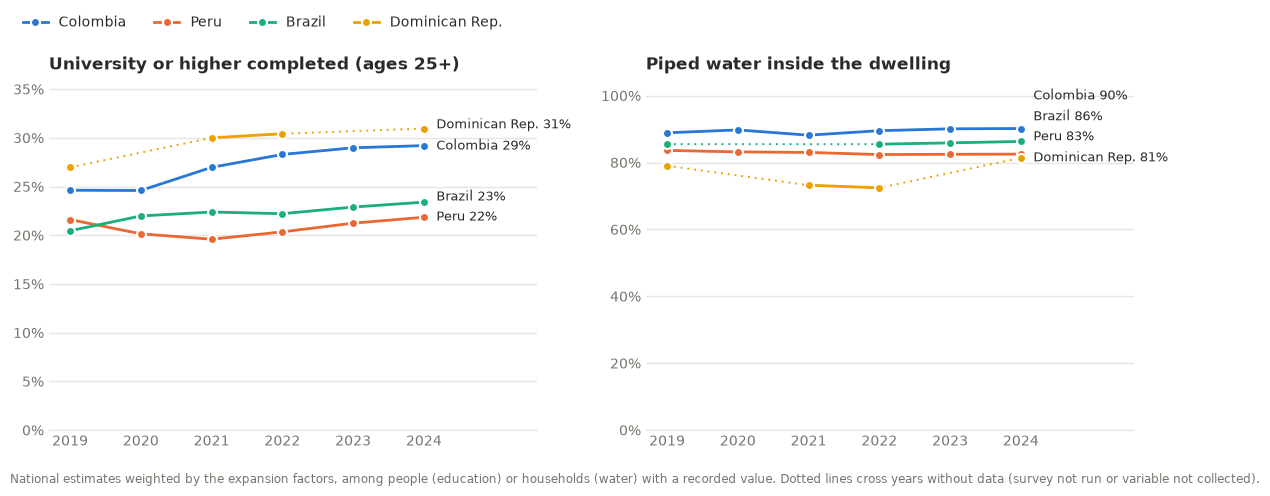

series  piped_water                                university           \
COUNTRY      Brazil Colombia Dominican Rep.   Peru     Brazil Colombia   
YEAR                                                                     
2019          0.855    0.889          0.790  0.836      0.205    0.246   
2020            NaN    0.897            NaN  0.832      0.220    0.246   
2021            NaN    0.882          0.732  0.830      0.224    0.270   
2022          0.855    0.895          0.724  0.824      0.222    0.283   
2023          0.859    0.901            NaN  0.825      0.229    0.290   
2024          0.863    0.902          0.814  0.825      0.234    0.292   

series                         
COUNTRY Dominican Rep.   Peru  
YEAR                           
2019             0.270  0.216  
2020               NaN  0.201  
2021             0.300  0.196  
2022             0.304  0.203  
2023               NaN  0.212  
2024             0.310  0.218

In [9]:
# Population-weighted national estimates straight from the records: university education (ages 25+)
# and piped water inside the dwelling, by country and year
import duckdb
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

COUNTRIES = {  # fixed order = fixed colors (categorical palette slots 1-4)
    "COL": ("Colombia", "#2a78d6"),
    "PER": ("Peru", "#eb6834"),
    "BRA": ("Brazil", "#1baf7a"),
    "DOM": ("Dominican Rep.", "#eda100"),
}
code_of = lambda v, text: int(next(k for k, lab in HARMONIZED[v]["VALUES"].items() if lab.startswith(text)))
UNIVERSITY, PIPED_INSIDE = code_of("P_EDUCATION", "University"), code_of("H_WATER", "Piped inside")
SERIES = {  # name: (title, SQL)  - shares among records with a recorded value (code 0 = Missing)
    "university": (f"University or higher completed (ages {EDUCATION_MIN_AGE}+)", f'''
        SELECT COUNTRY, YEAR, SUM(WEIGHT) FILTER (WHERE P_EDUCATION = {UNIVERSITY}) / SUM(WEIGHT) AS value
        FROM persons WHERE P_AGE >= {EDUCATION_MIN_AGE} AND P_EDUCATION <> 0 GROUP BY ALL'''),
    "piped_water": ("Piped water inside the dwelling", f'''
        SELECT COUNTRY, YEAR, SUM(WEIGHT) FILTER (WHERE H_WATER = {PIPED_INSIDE}) / SUM(WEIGHT) AS value
        FROM households WHERE H_WATER <> 0 GROUP BY ALL'''),
}
with duckdb.connect(str(DUCKDB_FILE), read_only=True) as con:
    ts = pd.concat([con.sql(sql).df().assign(series=name) for name, (_, sql) in SERIES.items()])

INK, MUTED, GRID = "#2b2a27", "#77756d", "#e7e5df"
years = list(range(FIRST_YEAR, LAST_YEAR + 1))


def spread(values, min_gap):
    # Nudge end labels apart so they never overlap (keeps their order)
    order = sorted(range(len(values)), key=lambda i: values[i])
    placed = list(values)
    for a, b in zip(order, order[1:]):
        placed[b] = max(placed[b], placed[a] + min_gap)
    return placed


plt.rcParams.update({"font.size": 10, "axes.titlesize": 12})
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, (name, (title, _)) in zip(axes, SERIES.items()):
    ends = []
    for code, (country, color) in COUNTRIES.items():
        d = ts[(ts.series == name) & (ts.COUNTRY == code)].set_index("YEAR")["value"].reindex(years)   # gaps stay gaps
        if d.notna().any():
            known = d.dropna()   # dotted line across years without data, solid line between consecutive years
            ax.plot(known.index, known.values, color=color, lw=1.4, ls=(0, (1, 2.5)), zorder=2)
            ax.plot(years, d.values, color=color, lw=2, marker="o", ms=6.5,
                    markeredgecolor="white", markeredgewidth=1.5, label=country, zorder=3)
            last = d.last_valid_index()
            ends.append((country, last, d[last]))
    ax.set_ylim(0, max(0.1, max(v for _, _, v in ends) * 1.15))
    for (country, x, value), y in zip(ends, spread([v for _, _, v in ends], 0.06 * ax.get_ylim()[1])):
        ax.annotate(f"{country} {value:.0%}", (x, y), xytext=(9, 0), textcoords="offset points",
                    va="center", color=INK, fontsize=9)
    ax.set_title(title, loc="left", color=INK, fontweight="bold", pad=10)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
    ax.set_xticks(years)
    ax.set_xlim(years[0] - 0.3, years[-1] + 1.6)
    ax.grid(axis="y", color=GRID, lw=1)
    ax.set_axisbelow(True)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GRID)
    ax.tick_params(colors=MUTED, length=0)

fig.legend(*axes[0].get_legend_handles_labels(), loc="upper left", ncol=4, frameon=False,
           bbox_to_anchor=(0.01, 1.0), labelcolor=INK, handlelength=1.8)
fig.text(0.01, 0.0, "National estimates weighted by the expansion factors, among people (education) or households (water) "
         "with a recorded value. Dotted lines cross years without data (survey not run or variable not collected).",
         color=MUTED, fontsize=8.5)
fig.tight_layout(rect=(0, 0.04, 1, 0.92))
plt.show()

# Table view with the exact values
display(ts.pivot_table(index="YEAR", columns=["series", "COUNTRY"], values="value").round(3)
        .rename(columns={c: n for c, (n, _) in COUNTRIES.items()}, level=1))

## 7. Exploratory data analysis

Overview of the harmonized records, read from the DuckDB database. All proportions are weighted with `WEIGHT`.

**Sample**: records per survey, table and year, and the type of weight of each year (`relative` weights are valid for proportions, not for totals).

In [10]:
# Exploratory data analysis on the record tables and the shares (DuckDB). Proportions are weighted with WEIGHT.
import textwrap

import duckdb
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap

con = duckdb.connect(str(DUCKDB_FILE), read_only=True)
COUNTRY = {"COL": "Colombia", "PER": "Peru", "BRA": "Brazil", "DOM": "Dominican Rep."}
COUNTRY_COLOR = {"COL": "#2a78d6", "PER": "#eb6834", "BRA": "#1baf7a", "DOM": "#eda100"}   # fixed per country
CATEGORY_COLOR = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
MISSING_COLOR = "#c4c2ba"   # neutral gray, reserved for Missing
SEQUENTIAL = LinearSegmentedColormap.from_list("blue", ["#f4f8fd", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
INK, MUTED, GRID = "#2b2a27", "#77756d", "#e7e5df"
plt.rcParams.update({"font.size": 9.5, "axes.titlesize": 11, "axes.titlecolor": INK, "axes.labelcolor": MUTED,
                     "xtick.color": MUTED, "ytick.color": MUTED, "axes.edgecolor": GRID})


def clean_axes(ax, grid_axis="x"):
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GRID)
    ax.tick_params(length=0)
    if grid_axis:
        ax.grid(axis=grid_axis, color=GRID, lw=1)
        ax.set_axisbelow(True)


def table_of(variable):
    return "households" if variable in HOUSEHOLD_VARS else "persons"


def label_of(variable, code):
    return "Missing" if code == 0 else HARMONIZED[variable]["VALUES"].get(str(code), f"code {code}")


# ---- 1. Sample: records per survey, table and year
sizes = con.sql('''
    SELECT SURVEY, 'households' AS records, YEAR, COUNT(*) AS n FROM households GROUP BY ALL
    UNION ALL
    SELECT SURVEY, 'persons', YEAR, COUNT(*) FROM persons GROUP BY ALL
''').df()
display(sizes.pivot_table(index=["SURVEY", "records"], columns="YEAR", values="n").astype("Int64"))
if "WEIGHT_TYPE" in con.sql("DESCRIBE persons").df()["column_name"].tolist():
    display(con.sql('''
        SELECT SURVEY, YEAR, ANY_VALUE(WEIGHT_TYPE) AS weight_type FROM persons GROUP BY ALL ORDER BY ALL
    ''').df().pivot(index="SURVEY", columns="YEAR", values="weight_type"))

YEAR                  2019    2020    2021    2022    2023    2024
SURVEY  records                                                   
ENAHO   households   34565   34490   34245   34213   33886   33691
        persons     120052  118810  113057  113142  110792  108664
ENHOGAR households   34982    <NA>   32191   40260    <NA>   12011
        persons      96968    <NA>   84778  105611    <NA>   31818
GEIH    households  231831  143350  313708  304459  293511  290968
        persons     756063  795293  942977  919459  860802  829683
PNADC   households  150667    <NA>    <NA>  132587  139014  140385
        persons     443790  355436  335100  376821  383049  381815

YEAR,2019,2020,2021,2022,2023,2024
SURVEY,,,,,,
ENAHO,expansion,expansion,expansion,expansion,expansion,expansion
ENHOGAR,relative,NaN,expansion,expansion,NaN,expansion
GEIH,expansion,expansion,expansion,expansion,expansion,expansion
PNADC,expansion,expansion,expansion,expansion,expansion,expansion


**Coverage**: share of records with a valid value (not missing, not code 0) for each harmonized variable and survey-year. Empty cells are variables that the survey does not collect that year or that are not mapped.

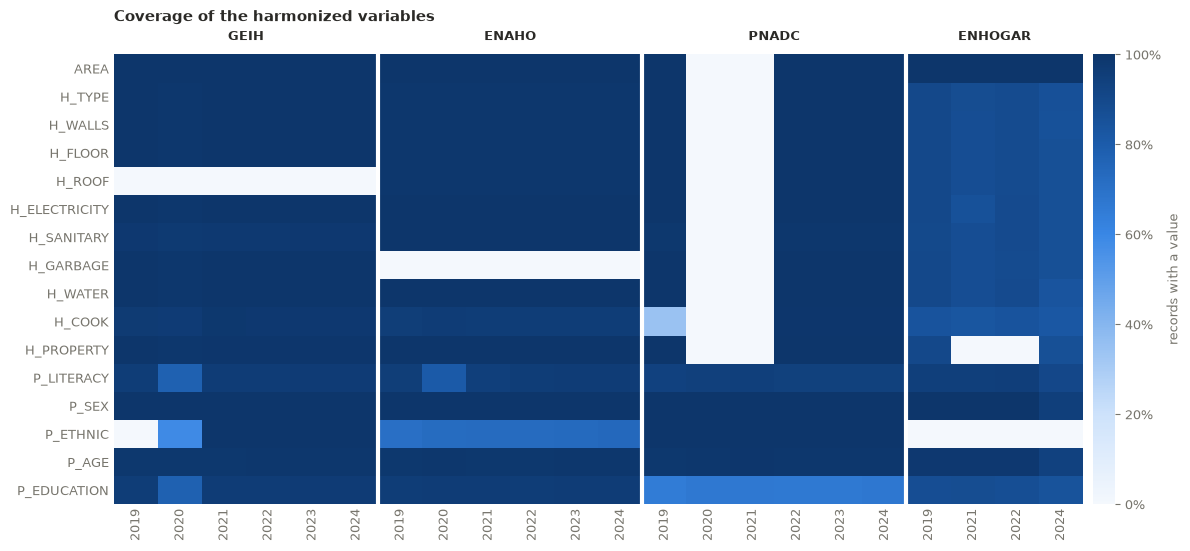

In [11]:
# ---- 2. Coverage: share of records with a valid value (not missing, not code 0), per variable and survey-year
cols = {}
for level in ("households", "persons"):
    variables = [v for v in HARMONIZED if table_of(v) == level]
    present = set(con.sql(f"DESCRIBE {level}").df()["column_name"])
    exprs = ", ".join(f"AVG(CASE WHEN {v} IS NOT NULL AND {v} <> 0 THEN 1 ELSE 0 END) AS {v}" if v in present
                      else f"0.0 AS {v}" for v in variables)
    cols[level] = con.sql(f"SELECT SURVEY, YEAR, {exprs} FROM {level} GROUP BY ALL").df().set_index(["SURVEY", "YEAR"])
coverage = cols["households"].join(cols["persons"], how="outer").fillna(0.0)
coverage = coverage.loc[[(s, y) for s in SURVEYS_TO_RUN for y in YEARS[s] if (s, y) in coverage.index]]

fig, ax = plt.subplots(figsize=(12, 5.6))
im = ax.imshow(coverage.T.values, cmap=SEQUENTIAL, vmin=0, vmax=1, aspect="auto")
ax.set_yticks(range(len(coverage.columns)), coverage.columns)
ax.set_xticks(range(len(coverage)), [str(y) for _, y in coverage.index], rotation=90)
start = 0
for survey, group in coverage.groupby(level=0, sort=False):
    ax.text(start + (len(group) - 1) / 2, -0.9, survey, ha="center", va="bottom", color=INK, fontweight="bold")
    if start:
        ax.axvline(start - 0.5, color="white", lw=3)
    start += len(group)
ax.tick_params(length=0)
for side in ax.spines.values():
    side.set_visible(False)
bar = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.01, format=mtick.PercentFormatter(1))
bar.outline.set_visible(False)
bar.set_label("records with a value")
ax.set_title("Coverage of the harmonized variables", loc="left", fontweight="bold", pad=24)
fig.tight_layout()
plt.show()

**Distributions**: weighted share of each category by country, in the latest year with data (education for ages 25 and over). Gray is *Missing*.

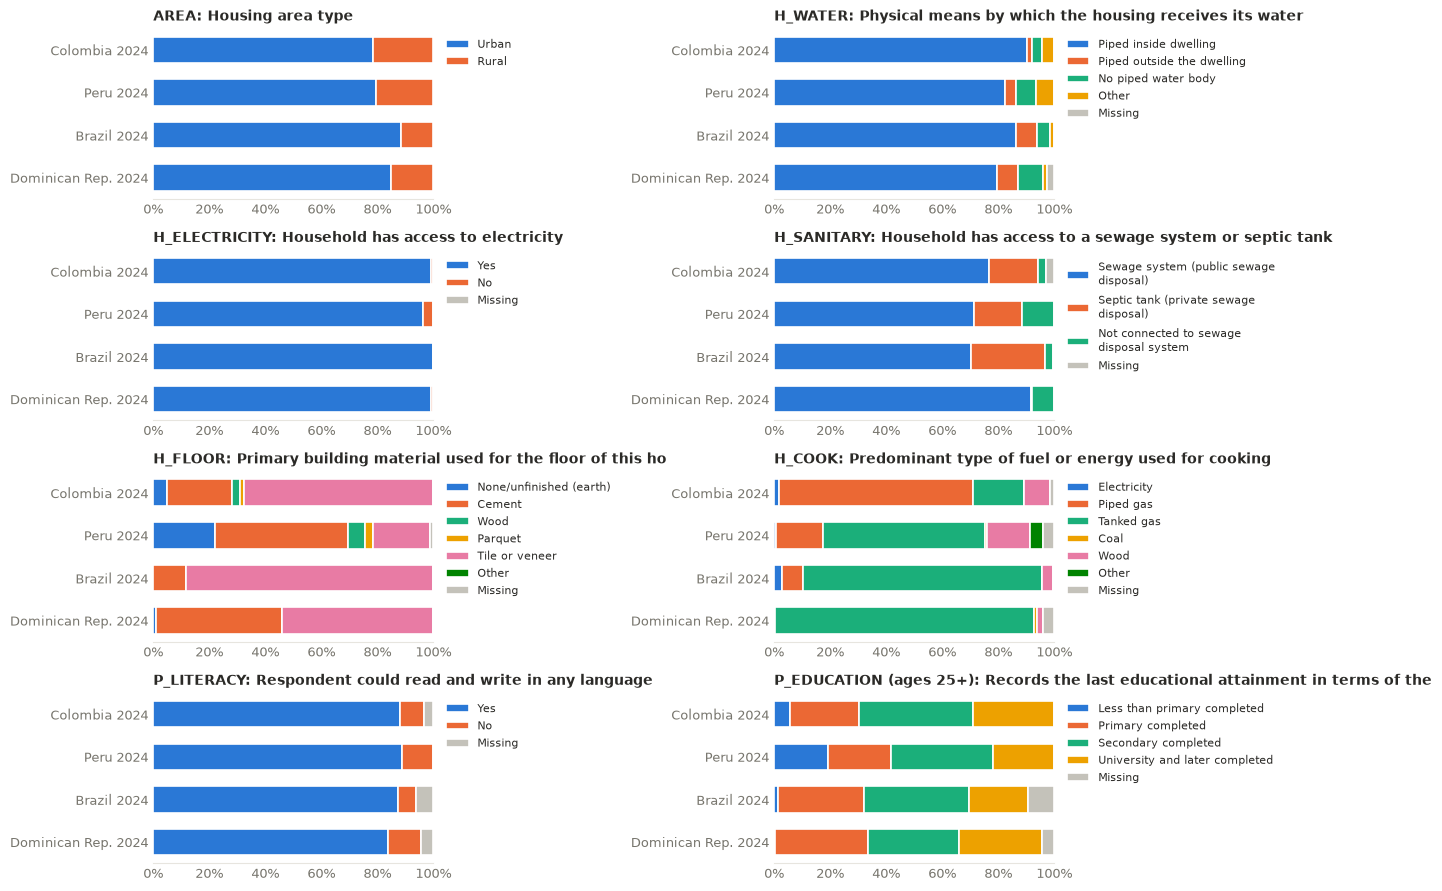

In [12]:
# ---- 3. Weighted distribution of each variable, by country, in the latest year with data
SHOW = ["AREA", "H_WATER", "H_ELECTRICITY", "H_SANITARY", "H_FLOOR", "H_COOK", "P_LITERACY", "P_EDUCATION"]


def latest_distribution(variable):
    level = table_of(variable)
    age = f"AND P_AGE >= {EDUCATION_MIN_AGE}" if variable == "P_EDUCATION" else ""
    return con.sql(f'''
        WITH latest AS (SELECT COUNTRY, MAX(YEAR) AS YEAR FROM {level}
                        WHERE {variable} IS NOT NULL AND {variable} <> 0 GROUP BY 1)
        SELECT t.COUNTRY, t.YEAR, t.{variable} AS code, SUM(t.WEIGHT) AS w
        FROM {level} t JOIN latest USING (COUNTRY, YEAR)
        WHERE t.{variable} IS NOT NULL AND t.WEIGHT IS NOT NULL {age}
        GROUP BY ALL
    ''').df()


fig, axes = plt.subplots(len(SHOW) // 2, 2, figsize=(13, 2.3 * len(SHOW) // 2))
for ax, variable in zip(axes.flat, SHOW):
    d = latest_distribution(variable)
    d["share"] = d["w"] / d.groupby("COUNTRY")["w"].transform("sum")
    countries = [c for c in COUNTRY if c in set(d.COUNTRY)]
    codes = sorted(c for c in d.code.unique() if c != 0) + ([0] if (d.code == 0).any() else [])
    left = np.zeros(len(countries))
    for i, code in enumerate(codes):
        values = [d.loc[(d.COUNTRY == c) & (d.code == code), "share"].sum() for c in countries]
        color = MISSING_COLOR if code == 0 else CATEGORY_COLOR[i % len(CATEGORY_COLOR)]
        ax.barh(range(len(countries)), values, left=left, color=color, height=0.62,
                edgecolor="white", linewidth=1.2, label=textwrap.fill(label_of(variable, code), 30))
        left += values
    years = d.groupby("COUNTRY")["YEAR"].first()
    ax.set_yticks(range(len(countries)), [f"{COUNTRY[c]} {years[c]}" for c in countries])
    ax.invert_yaxis()
    ax.set_xlim(0, 1)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
    title = variable + (f" (ages {EDUCATION_MIN_AGE}+)" if variable == "P_EDUCATION" else "")
    ax.set_title(f"{title}: {HARMONIZED[variable]['DESCRIPTION'].strip()[:55]}", loc="left", fontsize=10, fontweight="bold")
    ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0), frameon=False, fontsize=8, labelcolor=INK)
    clean_axes(ax, grid_axis=None)
fig.tight_layout()
plt.show()

**Age and sex**: population pyramids from the person records.

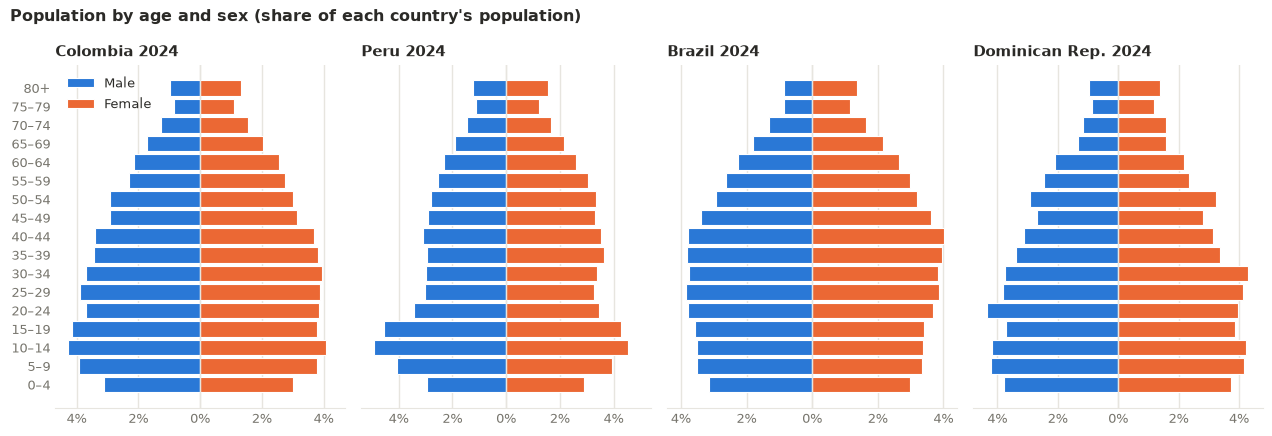

In [13]:
# ---- 4. Age pyramids (weighted), latest year of each country
pyramid = con.sql('''
    WITH latest AS (SELECT COUNTRY, MAX(YEAR) AS YEAR FROM persons WHERE P_AGE IS NOT NULL GROUP BY 1)
    SELECT p.COUNTRY, p.YEAR, LEAST(FLOOR(p.P_AGE / 5) * 5, 80)::INT AS age, p.P_SEX AS sex, SUM(p.WEIGHT) AS w
    FROM persons p JOIN latest USING (COUNTRY, YEAR)
    WHERE p.P_AGE IS NOT NULL AND p.P_SEX IN (1, 2) AND p.WEIGHT IS NOT NULL
    GROUP BY ALL
''').df()
pyramid["share"] = pyramid["w"] / pyramid.groupby("COUNTRY")["w"].transform("sum")
countries = [c for c in COUNTRY if c in set(pyramid.COUNTRY)]
fig, axes = plt.subplots(1, len(countries), figsize=(3.2 * len(countries), 4.4), sharey=True)
ages = list(range(0, 85, 5))
for ax, country in zip(np.atleast_1d(axes), countries):
    d = pyramid[pyramid.COUNTRY == country]
    male = [-d.loc[(d.age == a) & (d.sex == 1), "share"].sum() for a in ages]
    female = [d.loc[(d.age == a) & (d.sex == 2), "share"].sum() for a in ages]
    ax.barh(ages, male, height=4.2, color=CATEGORY_COLOR[0], label="Male", edgecolor="white", linewidth=0.8)
    ax.barh(ages, female, height=4.2, color=CATEGORY_COLOR[1], label="Female", edgecolor="white", linewidth=0.8)
    lim = max(max(female), -min(male)) * 1.1
    ax.set_xlim(-lim, lim)
    ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{abs(x):.0%}"))
    ax.set_yticks(ages, [f"{a}–{a + 4}" if a < 80 else "80+" for a in ages])
    ax.axvline(0, color=GRID, lw=1)
    ax.set_title(f"{COUNTRY[country]} {int(d.YEAR.iloc[0])}", loc="left", fontweight="bold")
    clean_axes(ax)
np.atleast_1d(axes)[0].legend(loc="upper left", frameon=False, labelcolor=INK)
fig.suptitle("Population by age and sex (share of each country's population)", x=0.01, ha="left",
             color=INK, fontweight="bold")
fig.tight_layout()
plt.show()

**Subnational variation**: each dot is a subnational unit in the latest year (`shares` table), the black line the median unit.

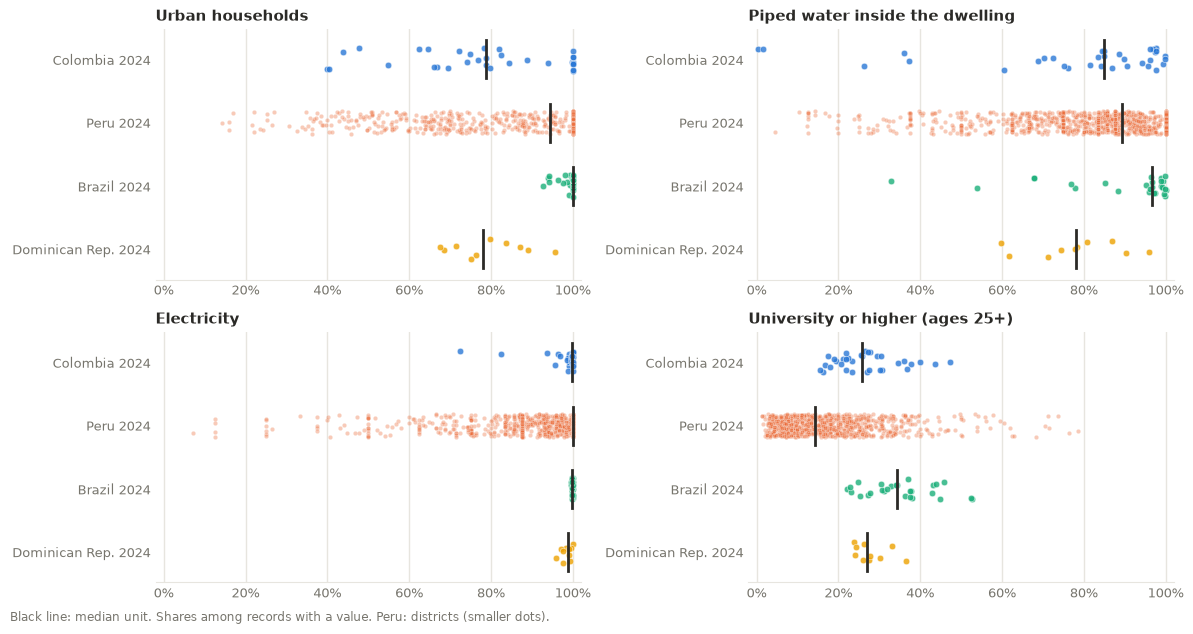

In [14]:
# ---- 5. Subnational variation: each dot is a unit (department, district, state capital or region), latest year
INDICATORS = {  # share column: (title, Missing column of the same variable)
    "AREA_Urban": ("Urban households", "AREA_Missing"),
    "H_WATER_Piped_inside_dwelling": ("Piped water inside the dwelling", "H_WATER_Missing"),
    "H_ELECTRICITY_Yes": ("Electricity", "H_ELECTRICITY_Missing"),
    "P_EDUCATION_University_and_later_completed": (f"University or higher (ages {EDUCATION_MIN_AGE}+)", "P_EDUCATION_Missing"),
}
latest = con.sql("SELECT COUNTRY, MAX(YEAR) AS YEAR FROM shares GROUP BY 1").df()
s = con.sql("SELECT * FROM shares").df().merge(latest, on=["COUNTRY", "YEAR"])
fig, axes = plt.subplots(2, 2, figsize=(12, 6.2))
rng = np.random.default_rng(0)
for ax, (column, (title, missing)) in zip(axes.flat, INDICATORS.items()):
    for row, country in enumerate([c for c in COUNTRY if c in set(s.COUNTRY)]):
        d = s[s.COUNTRY == country]
        if column not in d or d[column].isna().all():
            continue
        values = d[column].astype(float)
        if missing in d:   # share among records with a value, as in the time series
            values = values / (1 - d[missing].astype(float).fillna(0))
        jitter = rng.uniform(-0.18, 0.18, len(values))
        ax.scatter(values, row + jitter, s=10 if country == "PER" else 22, alpha=0.35 if country == "PER" else 0.8,
                   color=COUNTRY_COLOR[country], edgecolor="white", linewidth=0.4)
        ax.plot([values.median()] * 2, [row - 0.3, row + 0.3], color=INK, lw=2)
    order = [c for c in COUNTRY if c in set(s.COUNTRY)]
    years = latest.set_index("COUNTRY")["YEAR"]
    ax.set_yticks(range(len(order)), [f"{COUNTRY[c]} {years[c]}" for c in order])
    ax.invert_yaxis()
    ax.set_xlim(-0.02, 1.02)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
    ax.set_title(title, loc="left", fontweight="bold")
    clean_axes(ax)
fig.text(0.01, -0.01, "Black line: median unit. Shares among records with a value. Peru: districts (smaller dots).",
         color=MUTED, fontsize=8.5)
fig.tight_layout()
plt.show()

**Summary**: weighted indicators per country and year.

In [15]:
# ---- 6. Weighted summary per country and year
summary = con.sql(f'''
    SELECT p.COUNTRY, p.YEAR,
           COUNT(*) AS persons,
           ROUND(SUM(p.WEIGHT * p.P_AGE) / SUM(p.WEIGHT) FILTER (WHERE p.P_AGE IS NOT NULL), 1) AS mean_age,
           ROUND(SUM(p.WEIGHT) FILTER (WHERE p.P_SEX = 2) / SUM(p.WEIGHT) FILTER (WHERE p.P_SEX IN (1, 2)), 3) AS female,
           ROUND(SUM(p.WEIGHT) FILTER (WHERE p.P_LITERACY = 1) / SUM(p.WEIGHT) FILTER (WHERE p.P_LITERACY IN (1, 2)), 3) AS literate,
           ROUND(SUM(p.WEIGHT) FILTER (WHERE p.P_EDUCATION = 4 AND p.P_AGE >= {EDUCATION_MIN_AGE})
                 / SUM(p.WEIGHT) FILTER (WHERE p.P_EDUCATION <> 0 AND p.P_AGE >= {EDUCATION_MIN_AGE}), 3) AS university_25plus
    FROM persons p GROUP BY ALL ORDER BY ALL
''').df()
summary["COUNTRY"] = summary["COUNTRY"].map(COUNTRY)
summary

,COUNTRY,YEAR,persons,mean_age,female,literate,university_25plus
0,Brazil,2019,443790,34.2,0.512,0.922,0.205
1,Brazil,2020,355436,34.5,0.512,0.927,0.220
2,Brazil,2021,335100,34.8,0.512,0.924,0.224
3,Brazil,2022,376821,35.1,0.512,0.921,0.222
4,Brazil,2023,383049,35.5,0.512,0.927,0.229
5,Brazil,2024,381815,35.9,0.512,0.929,0.234
6,Colombia,2019,756063,33.2,0.512,0.901,0.246
7,Colombia,2020,795293,33.4,0.512,0.900,0.246
8,Colombia,2021,942977,33.6,0.513,0.904,0.270
9,Colombia,2022,919459,33.9,0.513,0.905,0.283


**Maps**: years with data and households interviewed per year in each unit; gray units were never surveyed in the period. Boundaries come from `data_paper_shapefiles.zip` (municipalities merged into departments, states and regions; Peru by district) and are cached in `OUTPUT_DIR/boundaries/`.

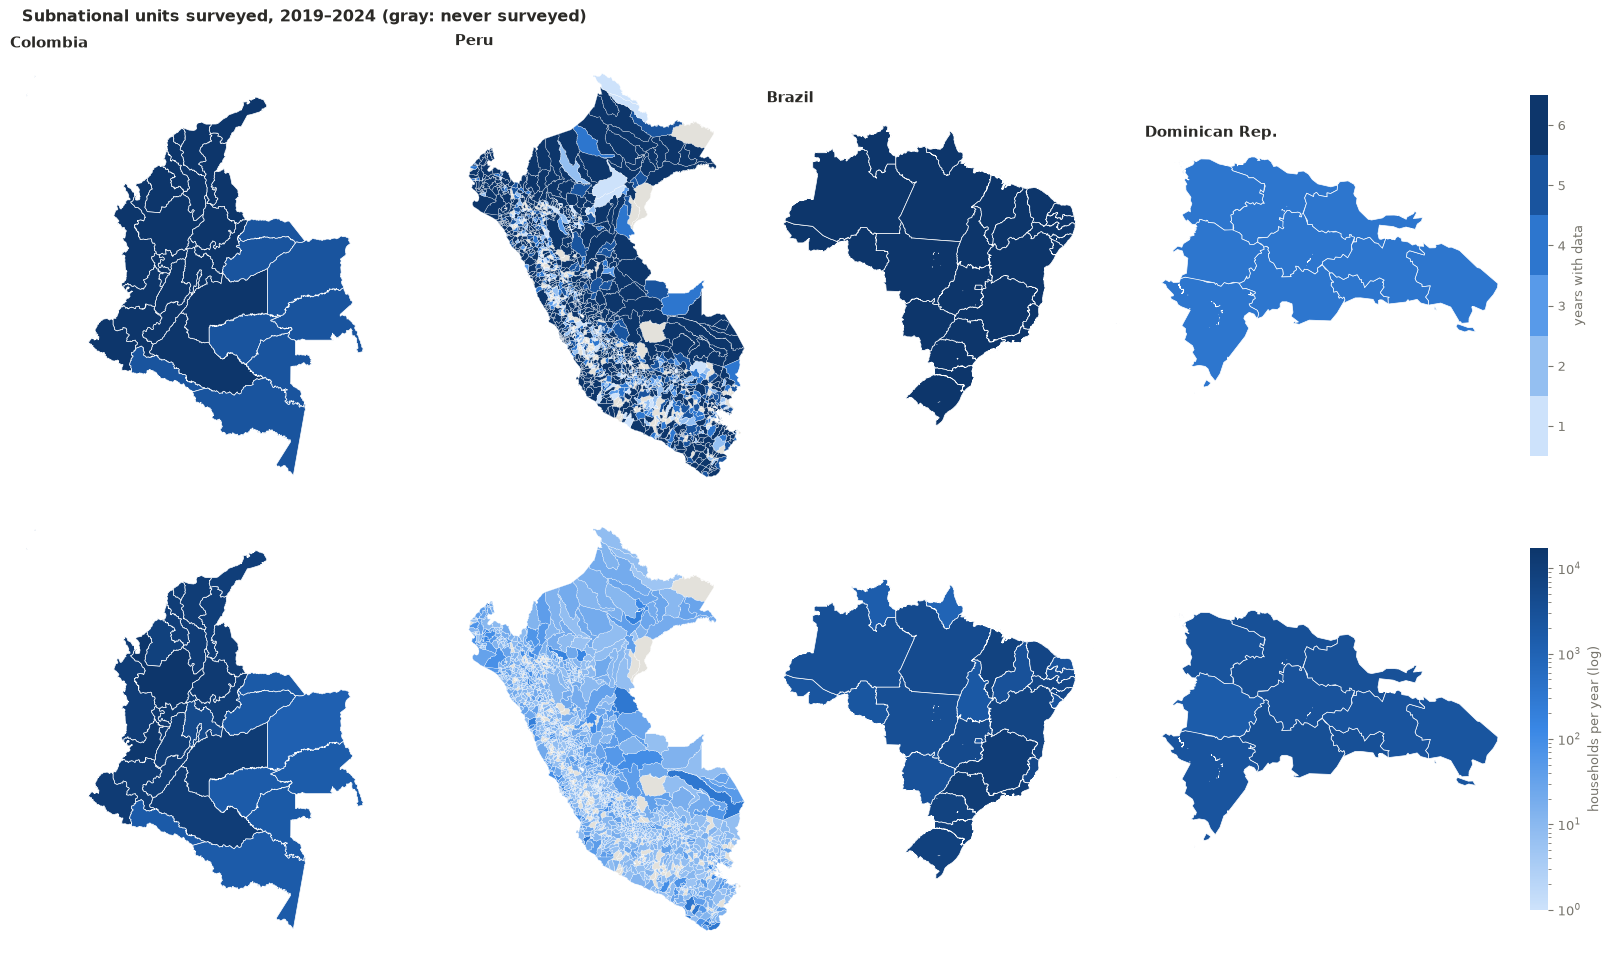

In [17]:
# ---- 8. Maps: years with data and households interviewed per year, for each unit (gray: never surveyed)
years_n = surveyed.groupby(["COUNTRY", "ADMIN_DIVISION"]).agg(years=("YEAR", "nunique"), per_year=("households", "mean")).reset_index()
fig, axes = plt.subplots(2, 4, figsize=(16, 9.5), layout="constrained")
max_years = max(len(y) for y in YEARS.values())
year_cmap = LinearSegmentedColormap.from_list("years", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"], N=max_years)
for col_i, country in enumerate(COUNTRY):
    g = shapes[country].merge(years_n[years_n.COUNTRY == country], on="ADMIN_DIVISION", how="left")
    for row, (column, kwargs, label) in enumerate([
        ("years", dict(cmap=year_cmap, vmin=0.5, vmax=max_years + 0.5), "years with data"),
        ("per_year", dict(cmap=COUNTS, norm=LogNorm(vmin=1, vmax=years_n.per_year.max())), "households per year (log)"),
    ]):
        ax = axes[row, col_i]
        if g[column].isna().any():
            g[g[column].isna()].plot(ax=ax, color=NOT_SURVEYED, edgecolor="white", linewidth=0.2)
        g[g[column].notna()].plot(ax=ax, column=column, edgecolor="white", linewidth=0.2 if country == "PER" else 0.5, **kwargs)
        ax.set_axis_off()
        if row == 0:
            ax.set_title(COUNTRY[country], loc="left", fontweight="bold")
        if col_i == 3:
            sm = plt.cm.ScalarMappable(cmap=kwargs["cmap"], norm=kwargs.get("norm") or plt.Normalize(kwargs["vmin"], kwargs["vmax"]))
            bar = fig.colorbar(sm, ax=axes[row, :], fraction=0.012, pad=0.01)
            bar.outline.set_visible(False)
            bar.set_label(label)
fig.suptitle(f"Subnational units surveyed, {FIRST_YEAR}–{LAST_YEAR} (gray: never surveyed)", x=0.01, ha="left",
             color=INK, fontweight="bold")
plt.show()

**Rural vs urban representation**: for each country and year, the share of people in rural and urban areas. Top, the people interviewed (unweighted sample); bottom, the population they represent (weighted). A rural share lower on top than below means rural areas are under-sampled. The table below gives both rural shares.

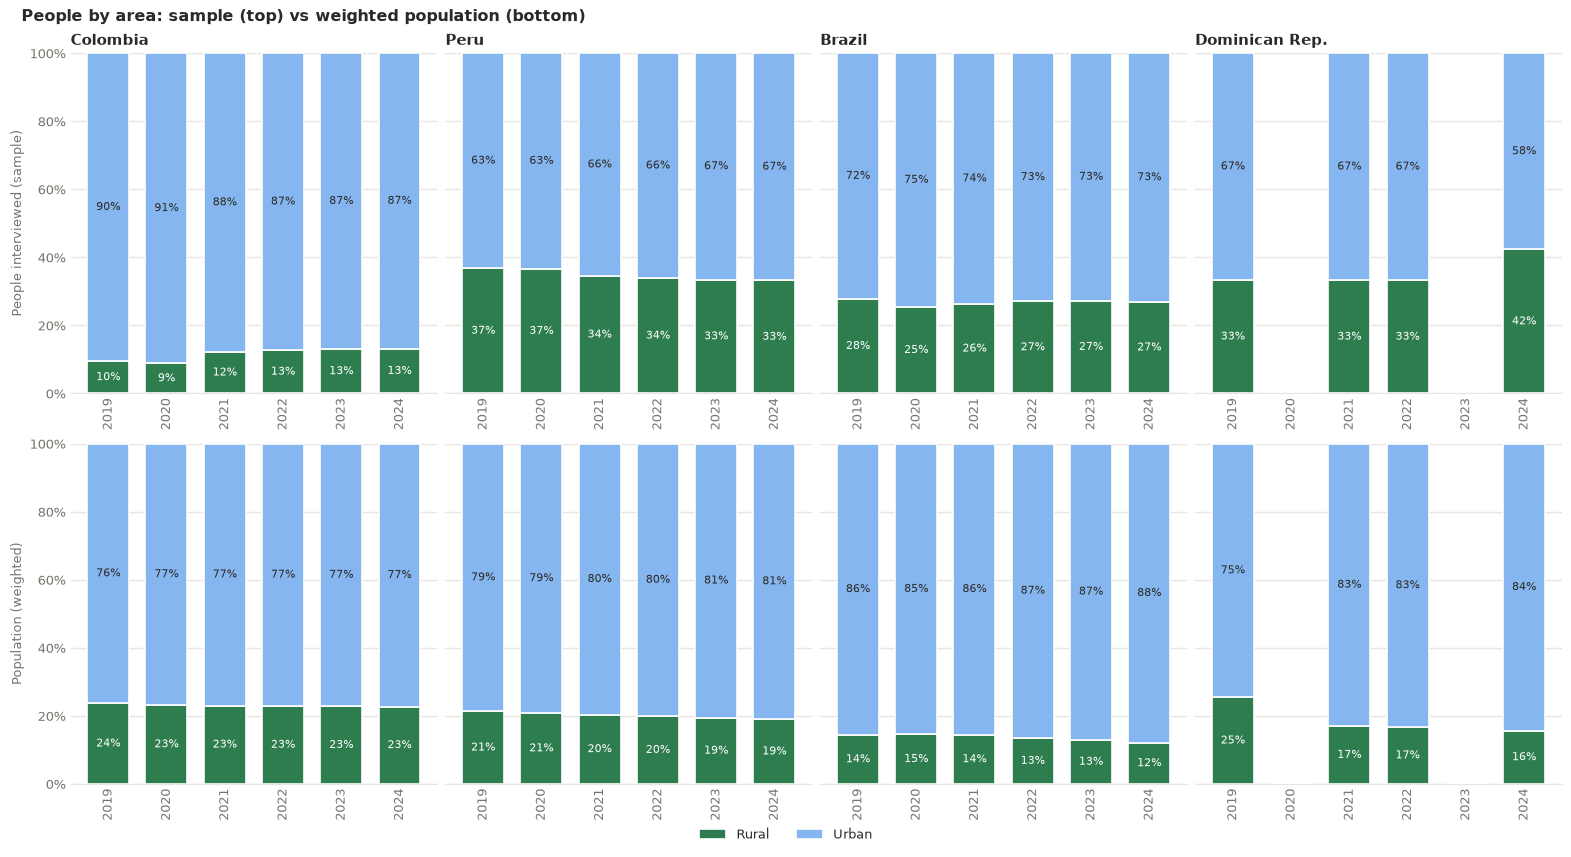

People interviewed (sample)                                 \
COUNTRY                      Brazil Colombia Dominican Rep.   Peru   
YEAR                                                                 
2019                          0.278    0.095          0.334  0.368   
2020                          0.255    0.089            NaN  0.366   
2021                          0.263    0.122          0.333  0.345   
2022                          0.271    0.127          0.332  0.339   
2023                          0.273    0.130            NaN  0.335   
2024                          0.270    0.131          0.423  0.332   

        Population (weighted)                                 
COUNTRY                Brazil Colombia Dominican Rep.   Peru  
YEAR                                                          
2019                    0.144    0.237          0.254  0.213  
2020                    0.145    0.232            NaN  0.208  
2021                    0.144    0.230          0.170  0.204  
2022                    0.134    0.229          0.167  0.199  
2023                    0.129    0.228            NaN  0.194  
2024                    0.121    0.227          0.156  0.190

In [19]:
# ---- 9. Rural vs urban representation
# Share of people in rural and urban areas, per country and year: top, the people interviewed (sample,
# unweighted); bottom, the population they represent (weighted). A rural share lower on top than below
# means rural areas are under-sampled.
area = con.sql(f'''
    SELECT COUNTRY, YEAR, AREA, COUNT(*) AS sample, SUM(WEIGHT) AS weighted
    FROM persons WHERE AREA IN (1, 2) AND YEAR BETWEEN {FIRST_YEAR} AND {LAST_YEAR} GROUP BY ALL
''').df()


def area_shares(measure):
    shares = area.pivot_table(index=["COUNTRY", "YEAR"], columns="AREA", values=measure, aggfunc="sum", fill_value=0)
    return shares.div(shares.sum(axis=1), axis=0).rename(columns={1: "Urban", 2: "Rural"}).reset_index()


ROWS = {"sample": ("People interviewed (sample)", area_shares("sample")),
        "weighted": ("Population (weighted)", area_shares("weighted"))}
AREA_COLORS = {"Rural": "#2e7d4f", "Urban": "#86b6ef"}   # rural at the base so its share reads from 0
TEXT_COLORS = {"Rural": "white", "Urban": INK}
years = list(range(FIRST_YEAR, LAST_YEAR + 1))
countries = [c for c in COUNTRY if c in set(area.COUNTRY)]
fig, axes = plt.subplots(2, len(countries), figsize=(3.9 * len(countries), 8.2), sharey=True,
                         layout="constrained", squeeze=False)
for r, (row_label, shares) in enumerate(ROWS.values()):
    for i, country in enumerate(countries):
        ax = axes[r, i]
        d = shares[shares.COUNTRY == country].set_index("YEAR").reindex(years)
        bottom = np.zeros(len(years))
        for name, color in AREA_COLORS.items():
            values = d[name].fillna(0).to_numpy() if name in d.columns else np.zeros(len(years))
            ax.bar(years, values, bottom=bottom, width=0.72, color=color, edgecolor="white", linewidth=1.2, label=name)
            for x, v, b in zip(years, values, bottom):
                if v >= 0.07:
                    ax.text(x, b + v / 2, f"{v:.0%}", ha="center", va="center", fontsize=8, color=TEXT_COLORS[name])
            bottom += values
        ax.set_ylim(0, 1)
        ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
        ax.set_xticks(years)
        ax.tick_params(axis="x", rotation=90)
        ax.set_title(COUNTRY[country] if r == 0 else "", loc="left", fontweight="bold")
        clean_axes(ax, grid_axis="y")
        if i == 0:
            ax.set_ylabel(row_label)
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="lower center", bbox_to_anchor=(0.5, -0.035), ncol=2,
           frameon=False, labelcolor=INK)
fig.suptitle("People by area: sample (top) vs weighted population (bottom)", x=0.01, ha="left", color=INK,
             fontweight="bold")
plt.show()

rural = pd.concat({label: s.assign(COUNTRY=s.COUNTRY.map(COUNTRY)).pivot(index="YEAR", columns="COUNTRY", values="Rural")
                   for label, s in ROWS.values()}, axis=1)
display(rural.round(3))   # rural share

**Estimated population per year**: the sum of the person weights per country and year, in millions, each country on its own scale. Years with only relative weights (ENHOGAR 2019) have no total. Brazil's total covers the whole country even though its units are state capitals.

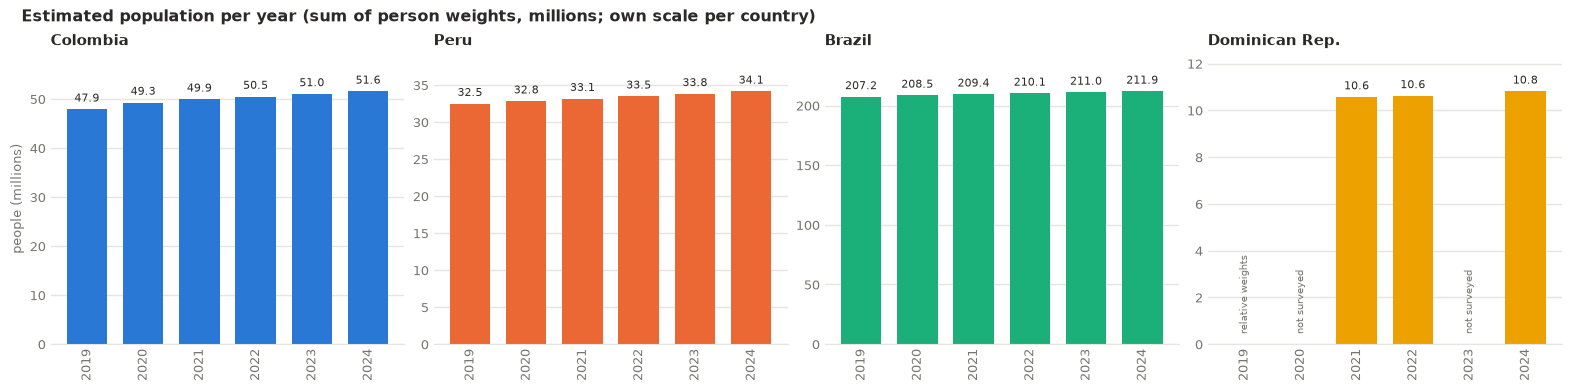

COUNTRY,Brazil,Colombia,Dominican Rep.,Peru
YEAR,,,,
2019,207.22,47.90,NaN,32.48
2020,208.47,49.27,NaN,32.82
2021,209.40,49.94,10.57,33.15
2022,210.15,50.50,10.62,33.48
2023,210.97,51.03,NaN,33.81
2024,211.85,51.55,10.81,34.15


In [20]:
# ---- 10. Estimated population per year
# Sum of the person weights per country and year (expansion weights only: relative weights do not add up to a
# population). Each country has its own scale.
population = con.sql(f'''
    SELECT COUNTRY, YEAR, ANY_VALUE(WEIGHT_TYPE) AS weight_type, SUM(WEIGHT) / 1e6 AS millions
    FROM persons WHERE YEAR BETWEEN {FIRST_YEAR} AND {LAST_YEAR} GROUP BY ALL
''').df()
population.loc[population.weight_type != "expansion", "millions"] = np.nan

years = list(range(FIRST_YEAR, LAST_YEAR + 1))
countries = [c for c in COUNTRY if c in set(population.COUNTRY)]
fig, axes = plt.subplots(1, len(countries), figsize=(3.9 * len(countries), 3.8), layout="constrained", squeeze=False)
for i, (ax, country) in enumerate(zip(axes[0], countries)):
    d = population[population.COUNTRY == country].set_index("YEAR").reindex(years)
    values = d.millions.to_numpy(dtype=float)
    top = np.nanmax(values) if np.isfinite(values).any() else 1
    ax.bar(years, np.nan_to_num(values), width=0.72, color=COUNTRY_COLOR[country])
    for x, v, kind in zip(years, values, d.weight_type):
        if np.isfinite(v):
            ax.text(x, v + top * 0.02, f"{v:.1f}", ha="center", va="bottom", fontsize=8, color=INK)
        else:
            note = "relative weights" if isinstance(kind, str) else "not surveyed"
            ax.text(x, top * 0.04, note, ha="center", va="bottom", fontsize=7.5, color=MUTED, rotation=90)
    ax.set_ylim(0, top * 1.15)
    ax.set_xticks(years)
    ax.tick_params(axis="x", rotation=90)
    ax.set_title(COUNTRY[country], loc="left", fontweight="bold")
    clean_axes(ax, grid_axis="y")
    if i == 0:
        ax.set_ylabel("people (millions)")
fig.suptitle("Estimated population per year (sum of person weights, millions; own scale per country)",
             x=0.01, ha="left", color=INK, fontweight="bold")
plt.show()

display(population.assign(COUNTRY=population.COUNTRY.map(COUNTRY))
        .pivot(index="YEAR", columns="COUNTRY", values="millions").round(2))